## Quantum Shor's Algorithm

### Here I am going to attempt creating Shor's Algorithm based on the lecture notes from Chen

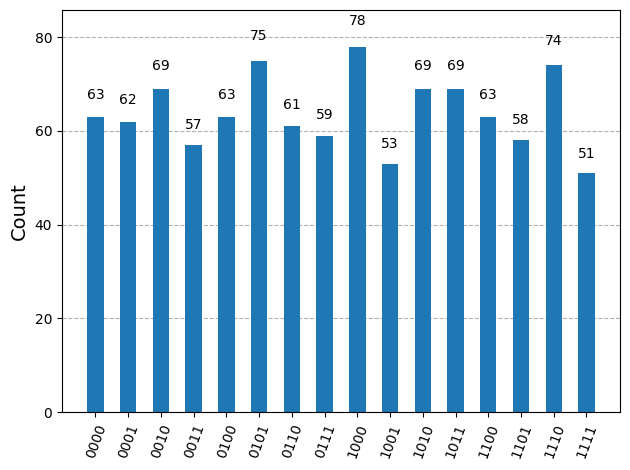

In [ ]:
# Implementation of Quantum Fourier Transform

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

num = 4
backend = AerSimulator()

q = QuantumRegister(num, 'q')
c = ClassicalRegister(num, 'c')

qc = QuantumCircuit(q,c)

for i in range(0, num):
    if i % 2 == 0:
        qc.x(q[i])


qc.compose(QFTGate(num), inplace = True)
qc.measure(q,c)

circ = transpile(qc, backend)
result = backend.run(circ, shots = 1024).result()
counts = result.get_counts(circ)


plot_histogram(counts)



### Implementation of Quantum Shoor's Aglorithm hadamard gates

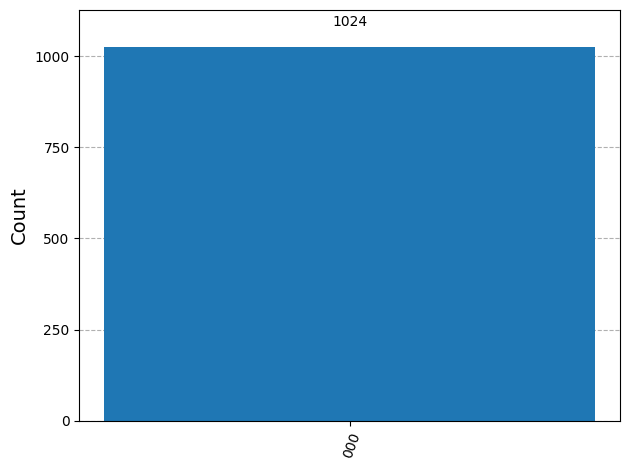

In [110]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

num = 3
backend = AerSimulator()

q = QuantumRegister(num, 'q')
c = ClassicalRegister(num, 'c')

qc = QuantumCircuit(q,c)

for i in range(0, num):
    qc.h(q[i])   

qc.compose(QFTGate(num), inplace = True)
    
qc.measure(q,c)

circ = transpile(qc, backend)
result = backend.run(circ, shots = 1024).result()
counts = result.get_counts(circ)


plot_histogram(counts)

### Quantum Phase Estimation

{'0010': 887, '0001': 65, '1010': 2, '1110': 4, '0100': 8, '1100': 3, '0011': 24, '0000': 9, '1101': 5, '1111': 7, '1001': 1, '0110': 3, '1000': 1, '0111': 2, '0101': 3}


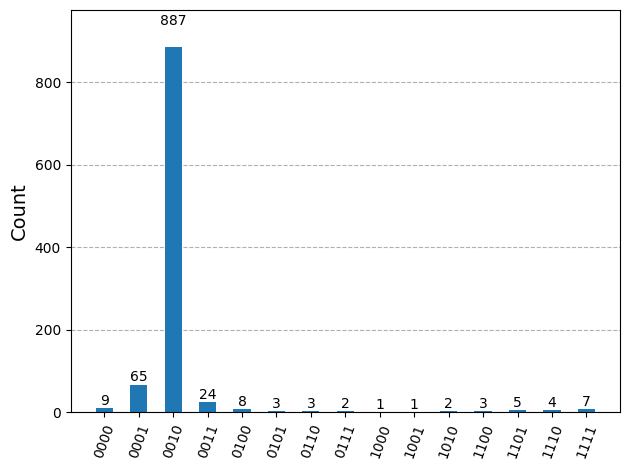

In [100]:
from qiskit.circuit.library import QFTGate
from qiskit.circuit import AnnotatedOperation, InverseModifier
from qiskit_aer import AerSimulator
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.visualization import plot_histogram
import cmath

n = 5
t = 1/9 # theta

backend = AerSimulator()

A  = QuantumRegister(n-1, 'A')
W = QuantumRegister(1, 'W')
C = ClassicalRegister(n-1, 'c')

pqc = QuantumCircuit(A, W, C)

pqc.x(W[0])

pqc.h(A)

for m in range (n - 1):
    pqc.cp(2*t*np.pi*(2**m), A[m], W[0]) 
    
iQFT = QFTGate(n-1).inverse(annotated=True)

pqc.append(iQFT, A)
counts = pqc.measure(A, C)

circ = transpile(pqc, backend)
result = backend.run(circ, shots = 1024).result()
counts = result.get_counts(circ)
print(counts)
plot_histogram(counts)
#pqc.draw("mpl")


### Quantum Grover's Algorithm

{'0100': 1024}


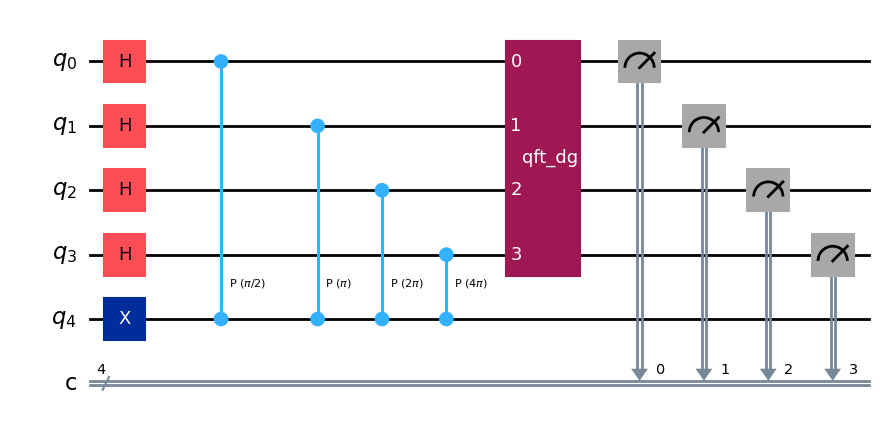

In [ ]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import numpy as np

A = QuantumRegister(4, 'A')
C = ClassicalRegister(4, 'C')

qc = QuantumCircuit(A, C)
